# ENGE707 Kaggle Competition - Assessment 3

## Task 1 : Dataset Exploration and Understanding

In [1]:
"""01 Data Exploration: Dataset Structure

Inspects the structure of the training and test data before any modelling.
Each check prints a PASS/FAIL result so the output can be used as evidence in the report (Task 1.2).

Run from the project folder:  python 01_data_structure.py
"""

# %% Configuration
# All paths are defined once here. Adjust `DATA_DIR` to wherever the Kaggle files are stored.
from pathlib import Path
from collections import Counter

import pandas as pd
from PIL import Image

DATA_DIR = Path("data")                      # folder containing train/, test/ and the CSV files
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
SAMPLE_SUB_CSV = DATA_DIR / "sample_submission.csv"
OUTPUT_DIR = Path("outputs")                 # where summary tables are saved for later scripts
OUTPUT_DIR.mkdir(exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
EXPECTED_CLASSES = {"CatEye", "DogEye", "CatFace", "DogFace",
                    "CatMouth", "DogMouth", "CatNose", "DogNose"}

print(f"Working directory: {Path.cwd()}")
missing = []
for p in [TRAIN_DIR, TEST_DIR, TRAIN_CSV, SAMPLE_SUB_CSV]:
    print(f"{'found  ' if p.exists() else 'MISSING'}  {p.resolve()}")
    if not p.exists():
        missing.append(p)
if missing:
    raise SystemExit("Some paths are missing. Set DATA_DIR (and TRAIN_CSV if the label file "
                     "has a different name) at the top of this script, then run it again.")

# %% 1. Load the CSV files
# `image_id` is read as text (`dtype=str`) so zero-padded IDs such as `00001` keep their leading zeros and match the filenames.
train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
sub_df = pd.read_csv(SAMPLE_SUB_CSV, dtype={"image_id": str})

print("train_labels.csv")
print(f"  shape: {train_df.shape}, columns: {list(train_df.columns)}")
print(train_df.head())

print("sample_submission.csv")
print(f"  shape: {sub_df.shape}, columns: {list(sub_df.columns)}")
print(sub_df.head())

# %% 2. Folder inventory
# Counts every file in each folder and groups them by extension, so unexpected files (hidden system files, non-images) are visible.
def inventory(folder):
    # Searches subfolders too, since Kaggle zips often unpack as train/train/...
    files = [f for f in folder.rglob("*") if f.is_file()]
    images = [f for f in files if f.suffix.lower() in IMAGE_EXTENSIONS]
    other = [f for f in files if f.suffix.lower() not in IMAGE_EXTENSIONS]
    subfolders = [d for d in folder.rglob("*") if d.is_dir()]
    return files, images, other, subfolders

folder_info = {}
for name, folder in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    if not folder.is_dir():
        raise SystemExit(f"Folder not found: {folder.resolve()}\n"
                         f"Set DATA_DIR at the top of this script to the folder containing train/ and test/.")
    files, images, other, subfolders = inventory(folder)
    folder_info[name] = images
    print(f"[{name}/]  ({folder.resolve()})")
    print(f"  total files:       {len(files)}")
    print(f"  image files:       {len(images)}")
    print(f"  extensions:        {dict(Counter(f.suffix.lower() for f in files))}")
    print(f"  non-image files:   {len(other)} {[f.name for f in other[:10]]}")
    print(f"  subfolders:        {len(subfolders)} {[str(d.relative_to(folder)) for d in subfolders[:10]]}")
    print(f"  example files:     {sorted(str(f.relative_to(folder)) for f in images)[:5]}")
    if not images:
        raise SystemExit(f"No image files found in {folder.resolve()}. "
                         f"Check DATA_DIR and the file extensions listed above.")

# %% 3. Training labels against training images
# Matches filenames (without extension) to `image_id` in both directions.
train_files = {f.stem: f for f in folder_info["train"]}
label_ids = set(train_df["image_id"])

labels_without_image = label_ids - set(train_files)
images_without_label = set(train_files) - label_ids
duplicate_ids = train_df["image_id"][train_df["image_id"].duplicated()].tolist()
unexpected_classes = set(train_df["class"].unique()) - EXPECTED_CLASSES

def check(description, passed, detail=""):
    print(f"[{'PASS' if passed else 'FAIL'}] {description} {detail}")

check("Row count matches image count:", len(train_df) == len(train_files),
      f"({len(train_df)} rows, {len(train_files)} images)")
check("Every label has a matching image:", not labels_without_image,
      f"({len(labels_without_image)} missing) {sorted(labels_without_image)[:5]}")
check("Every image has a label:", not images_without_label,
      f"({len(images_without_label)} unlabelled) {sorted(images_without_label)[:5]}")
check("All image_id values are unique:", not duplicate_ids,
      f"({len(duplicate_ids)} duplicates) {duplicate_ids[:5]}")
check("All class values are one of the eight expected classes:", not unexpected_classes,
      f"{sorted(unexpected_classes)}")
check("No missing values in train_labels.csv:", train_df.isna().sum().sum() == 0)

print("\nClasses found:", sorted(train_df["class"].unique()))

# %% 4. Test images against the sample submission
# Also inspects what the `class` column of the sample submission contains, which settles the exact label spelling expected by the grader (for example `DogEye` vs `DogEyes`).
test_files = {f.stem: f for f in folder_info["test"]}
sub_ids = set(sub_df["image_id"])

check("Submission row count matches test image count:", len(sub_df) == len(test_files),
      f"({len(sub_df)} rows, {len(test_files)} images)")
check("Every submission ID has a test image:", not (sub_ids - set(test_files)),
      f"({len(sub_ids - set(test_files))} missing) {sorted(sub_ids - set(test_files))[:5]}")
check("Every test image appears in the submission:", not (set(test_files) - sub_ids),
      f"({len(set(test_files) - sub_ids)} absent) {sorted(set(test_files) - sub_ids)[:5]}")
check("Submission IDs are unique:", not sub_df["image_id"].duplicated().any())

print("\nValues in sample_submission 'class' column:")
print(sub_df["class"].value_counts())
print("\nValues NOT in the training label set:",
      sorted(set(sub_df["class"].astype(str)) - EXPECTED_CLASSES))

# %% #ID ranges and overlap
# Both sets may number from `00001`, so the same ID can refer to different images in `train/` and `test/`. Paths must always include the folder.
def id_summary(ids, name):
    nums = sorted(int(i) for i in ids)
    gaps = (nums[-1] - nums[0] + 1) - len(nums)
    print(f"{name}: min {nums[0]}, max {nums[-1]}, count {len(nums)}, gaps in range {gaps}, "
          f"ID string lengths {sorted({len(i) for i in ids})}")

id_summary(label_ids, "train")
id_summary(sub_ids, "test ")
overlap = label_ids & sub_ids
print(f"IDs shared between train and test: {len(overlap)} (different images, same ID string)")

# %% 5. Basic image properties
# Reads only the image header (fast), recording format, colour mode and dimensions for every image.
# Files that fail to open are recorded rather than stopping the loop. The table is saved for reuse in the data quality section.
def image_properties(files, split):
    records = []
    for image_id, path in files.items():
        try:
            with Image.open(path) as img:
                records.append({"split": split, "image_id": image_id, "file": path.name,
                                "format": img.format, "mode": img.mode,
                                "width": img.width, "height": img.height, "error": None})
        except Exception as e:
            records.append({"split": split, "image_id": image_id, "file": path.name,
                            "format": None, "mode": None, "width": None, "height": None,
                            "error": type(e).__name__})
    return records

props = pd.DataFrame(image_properties(train_files, "train") + image_properties(test_files, "test"))
props.to_csv(OUTPUT_DIR / "image_properties.csv", index=False)

for split, g in props.groupby("split"):
    print(f"[{split}]  images: {len(g)}, failed to open: {g['error'].notna().sum()}")
    print(f"  formats: {g['format'].value_counts(dropna=False).to_dict()}")
    print(f"  modes:   {g['mode'].value_counts(dropna=False).to_dict()}")
    print(f"  width  min/median/max: {g['width'].min()} / {g['width'].median()} / {g['width'].max()}")
    print(f"  height min/median/max: {g['height'].min()} / {g['height'].median()} / {g['height'].max()}")
    print(f"  distinct (width, height) sizes: {g.groupby(['width', 'height']).ngroups}")

# %% 6. Summary table for the report

def describe(split, n_csv_rows, labelled, use):
    g = props[props["split"] == split]
    return {"Folder": f"{split}/",
            "Images": len(g),
            "CSV rows": n_csv_rows,
            "Format(s)": ", ".join(sorted(g["format"].dropna().unique())),
            "Colour mode(s)": ", ".join(sorted(g["mode"].dropna().unique())),
            "Size range (W x H)": f"{int(g['width'].min())}x{int(g['height'].min())} to "
                                  f"{int(g['width'].max())}x{int(g['height'].max())}",
            "Labelled": labelled,
            "Used for": use}

summary = pd.DataFrame([
    describe("train", len(train_df), "Yes (train_labels.csv)", "Training and validation"),
    describe("test", len(sub_df), "No", "Kaggle predictions only"),
])
summary.to_csv(OUTPUT_DIR / "dataset_structure_summary.csv", index=False)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(summary.to_string(index=False))

Working directory: /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/src
MISSING  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/src/data/train
MISSING  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/src/data/test
MISSING  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/src/data/train_labels.csv
MISSING  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/src/data/sample_submission.csv


SystemExit: Some paths are missing. Set DATA_DIR (and TRAIN_CSV if the label file has a different name) at the top of this script, then run it again.

/Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/.venv/lib/python3.14/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


### Class Distribution

Rows in train_labels.csv: 63660
Labels with a matching image: 63660 (dropped 0)

Images per class
          Images  Share (%)
class                      
CatEye     13884       21.8
DogEye     11580       18.2
CatFace     6942       10.9
DogFace     5790        9.1
CatMouth    6942       10.9
DogMouth    5790        9.1
CatNose     6942       10.9
DogNose     5790        9.1
Total      63660      100.0

Largest class(es):  CatEye (13884)
Smallest class(es): DogFace, DogMouth, DogNose (5790)
Imbalance ratio (largest / smallest): 2.40

By species:
  Cat     34710  (54.5%)
  Dog     28950  (45.5%)

By part:
  Eye     25464  (40.0%)
  Mouth   12732  (20.0%)
  Face    12732  (20.0%)
  Nose    12732  (20.0%)

Source-photo pattern check
  Cat: Face=6942, Mouth=6942, Nose=6942, Eye=13884  ->  Face=Mouth=Nose: True, Eye = 2 x Face: True
  Dog: Face=5790, Mouth=5790, Nose=5790, Eye=11580  ->  Face=Mouth=Nose: True, Eye = 2 x Face: True

Saved chart to outputs/figures/class_distribution.png


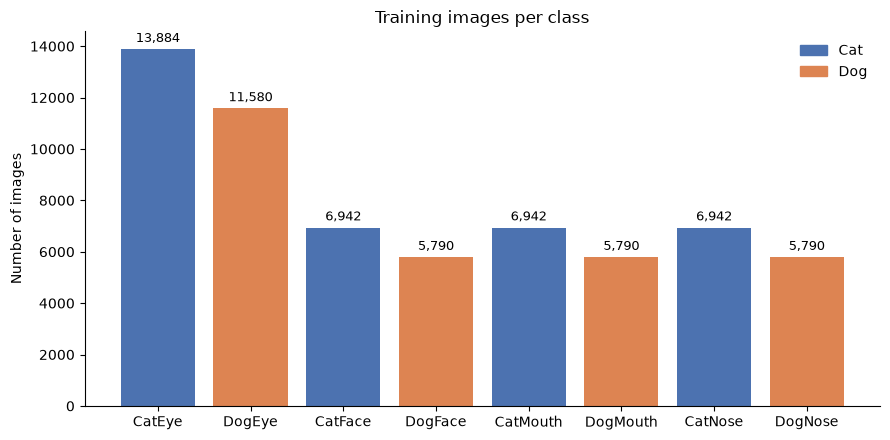

In [ ]:
"""02 Data Exploration: Class Distribution

Counts the images in each class and checks how balanced the dataset is (report Tasks 1.3 and 1.4).
Counts are taken from train_labels.csv and confirmed against the image files that actually exist,
so the reported numbers reflect usable training images.

Run from the project folder:  python 02_class_distribution.py
Requires: pandas, matplotlib
"""

# %% Configuration
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")                      # same setting as 01_data_structure.py
TRAIN_DIR = DATA_DIR / "train"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
CLASS_ORDER = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]

train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
print(f"Rows in {TRAIN_CSV.name}: {len(train_df)}")

# %% 1. Keep only labels whose image file exists
# If 01_data_structure.py reported every label matched an image, nothing is dropped here.
existing_ids = {f.stem for f in TRAIN_DIR.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS}
train_df["has_image"] = train_df["image_id"].isin(existing_ids)
print(f"Labels with a matching image: {train_df['has_image'].sum()} "
      f"(dropped {(~train_df['has_image']).sum()})")
df = train_df[train_df["has_image"]].copy()

# %% 2. Images per class
counts = df["class"].value_counts().reindex(CLASS_ORDER)
table = pd.DataFrame({"Images": counts, "Share (%)": (counts / counts.sum() * 100).round(1)})
table.loc["Total"] = [counts.sum(), 100.0]
table["Images"] = table["Images"].astype(int)
print("\nImages per class")
print(table.to_string())
table.to_csv(OUTPUT_DIR / "class_counts.csv")

# %% 3. Balance measures
# The eight classes combine species (Cat/Dog) and facial part (Eye/Face/Mouth/Nose),
# so each factor is summarised separately as well.
df["species"] = df["class"].str[:3]
df["part"] = df["class"].str[3:]

ratio = counts.max() / counts.min()
# Lists every class sharing the max or min, since several classes may tie.
print(f"\nLargest class(es):  {', '.join(counts[counts == counts.max()].index)} ({counts.max()})")
print(f"Smallest class(es): {', '.join(counts[counts == counts.min()].index)} ({counts.min()})")
print(f"Imbalance ratio (largest / smallest): {ratio:.2f}")

for factor in ["species", "part"]:
    s = df[factor].value_counts()
    print(f"\nBy {factor}:")
    for k, v in s.items():
        print(f"  {k:<6} {v:>6}  ({v / len(df) * 100:.1f}%)")

# %% 4. Check the source-photo pattern
# Hypothesis: each source photo yields one face, one mouth, one nose and two eye crops.
# If true, within each species Face = Mouth = Nose and Eye = 2 x Face.
print("\nSource-photo pattern check")
for sp in ["Cat", "Dog"]:
    face, mouth, nose, eye = (counts[f"{sp}{p}"] for p in ["Face", "Mouth", "Nose", "Eye"])
    print(f"  {sp}: Face={face}, Mouth={mouth}, Nose={nose}, Eye={eye}  ->  "
          f"Face=Mouth=Nose: {face == mouth == nose}, Eye = 2 x Face: {eye == 2 * face}")

# %% 5. Bar chart for the report
fig, ax = plt.subplots(figsize=(9, 4.5))
colours = ["#4C72B0" if c.startswith("Cat") else "#DD8452" for c in CLASS_ORDER]
bars = ax.bar(CLASS_ORDER, counts.values, color=colours)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3, fontsize=9)
ax.set_ylabel("Number of images")
ax.set_title("Training images per class")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"),
                   plt.Rectangle((0, 0), 1, 1, color="#DD8452")],
          labels=["Cat", "Dog"], frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "class_distribution.png", dpi=200)
print(f"\nSaved chart to {FIG_DIR / 'class_distribution.png'}")
plt.show()

### Data Quality Issues 

Images to check: 93103 (train 63660, test 29443)
  5000/93103 images  (2s)
  10000/93103 images  (4s)
  15000/93103 images  (6s)
  20000/93103 images  (9s)
  25000/93103 images  (11s)
  30000/93103 images  (13s)
  35000/93103 images  (15s)
  40000/93103 images  (17s)
  45000/93103 images  (19s)
  50000/93103 images  (21s)
  55000/93103 images  (23s)
  60000/93103 images  (26s)
  65000/93103 images  (28s)
  70000/93103 images  (30s)
  75000/93103 images  (32s)
  80000/93103 images  (34s)
  85000/93103 images  (36s)
  90000/93103 images  (38s)
  93103/93103 images  (40s)

1. CORRUPTED FILES: 0 of 93103 images could not be fully decoded

2. IMAGE SIZES
  [test] distinct sizes: 7786, width 8 to 1832 (median 82), height 9 to 1978 (median 80), non-square: 67.2%
    most common sizes: 40x40 (503), 50x50 (402), 80x80 (370), 30x30 (349), 60x60 (343)
    colour modes: {'RGB': 29443}
  [train] distinct sizes: 7861, width 4 to 2219 (median 84), height 4 to 2219 (median 80), non-square: 34.5%
    m

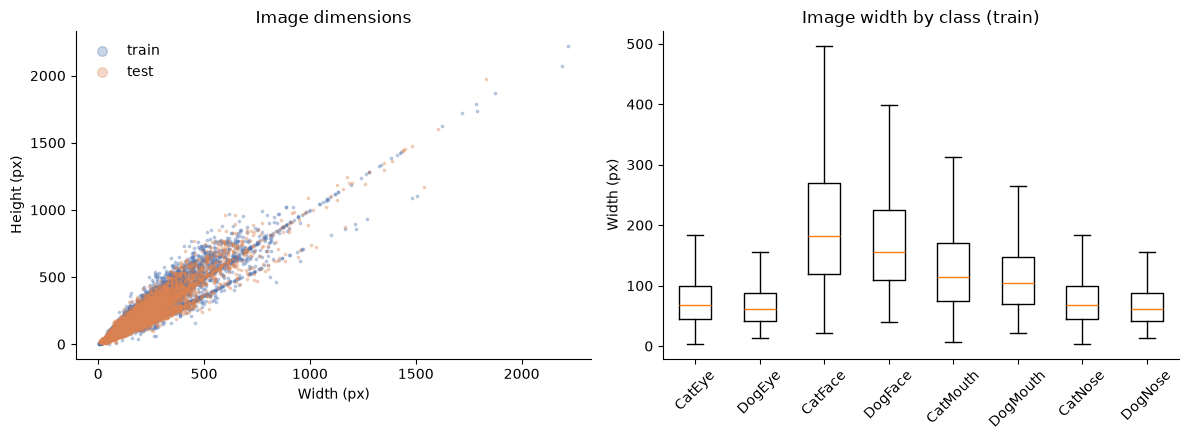

  saved outputs/figures/smallest_images.png


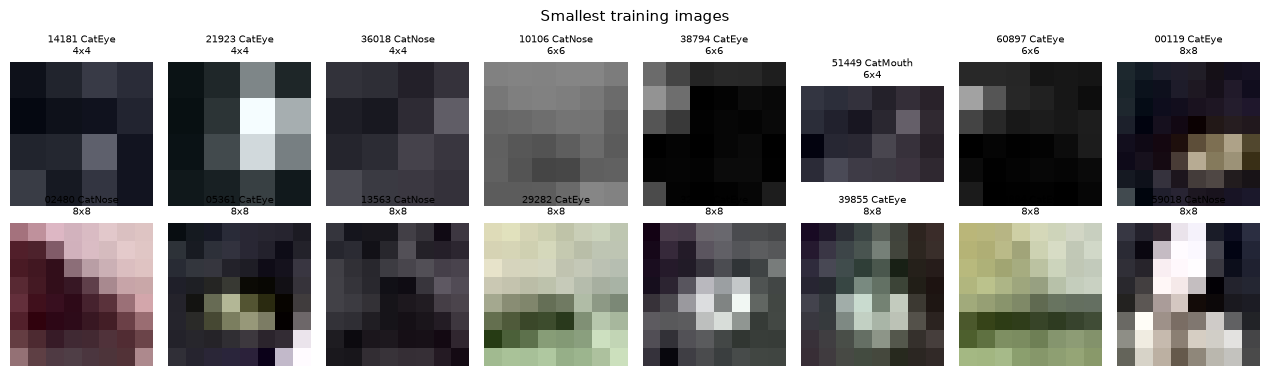


3. BLUR: sharpness median 197.7, bottom-1% cut-off 3.1; 932 images flagged as blurriest
  Blurriest-1% rate per class (train). An uneven spread suggests some classes are naturally softer:
  CatEye 1.4%, DogEye 2.0%, CatFace 0.0%, DogFace 0.0%, CatMouth 0.5%, DogMouth 0.0%, CatNose 2.6%, DogNose 1.2%
  saved outputs/figures/sharpness_distribution.png


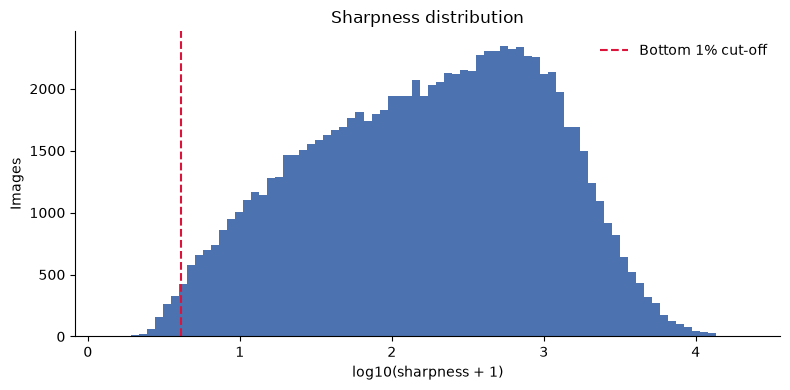

  saved outputs/figures/blurriest_images.png


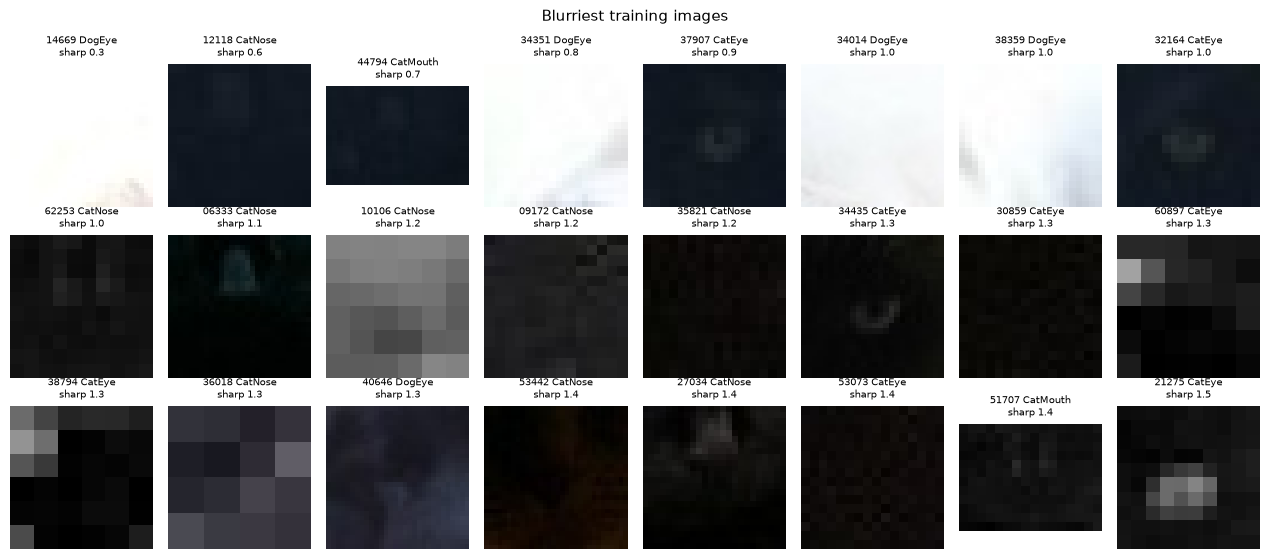


4. EXPOSURE: very dark 531, very bright 80, near-uniform 141
  saved outputs/figures/extreme_exposure.png


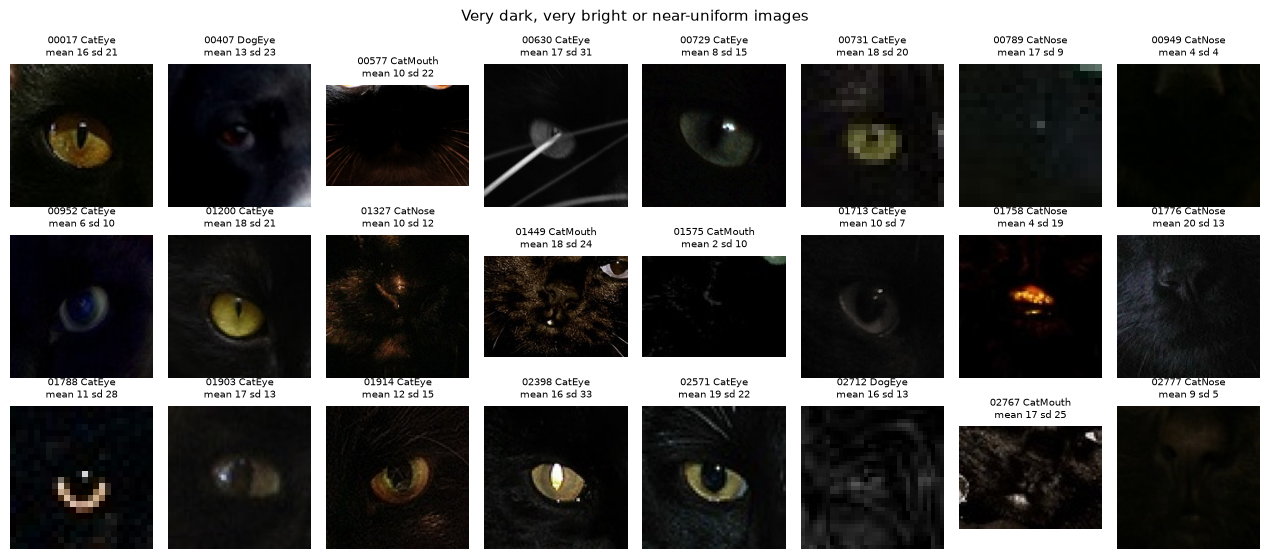


5. DUPLICATES
  Exact duplicates within train: 15 groups covering 30 images
    groups whose copies have DIFFERENT labels: 0
    train images that also appear in test: 0 (0 distinct pictures)
  Near duplicates within train: 40 groups covering 80 images
    groups whose copies have DIFFERENT labels: 0
    train images that also appear in test: 2 (2 distinct pictures)
  saved outputs/figures/near_duplicates.png


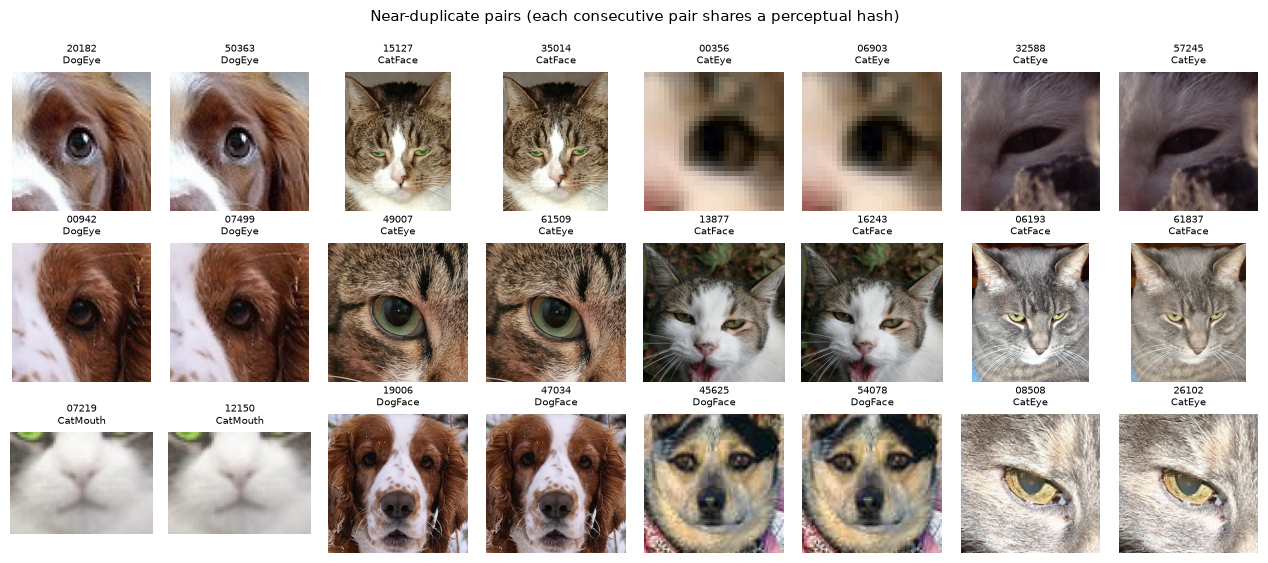


6. CLASS BOUNDARIES: review the per-class grid for ambiguous examples
  saved outputs/figures/class_samples_review.png


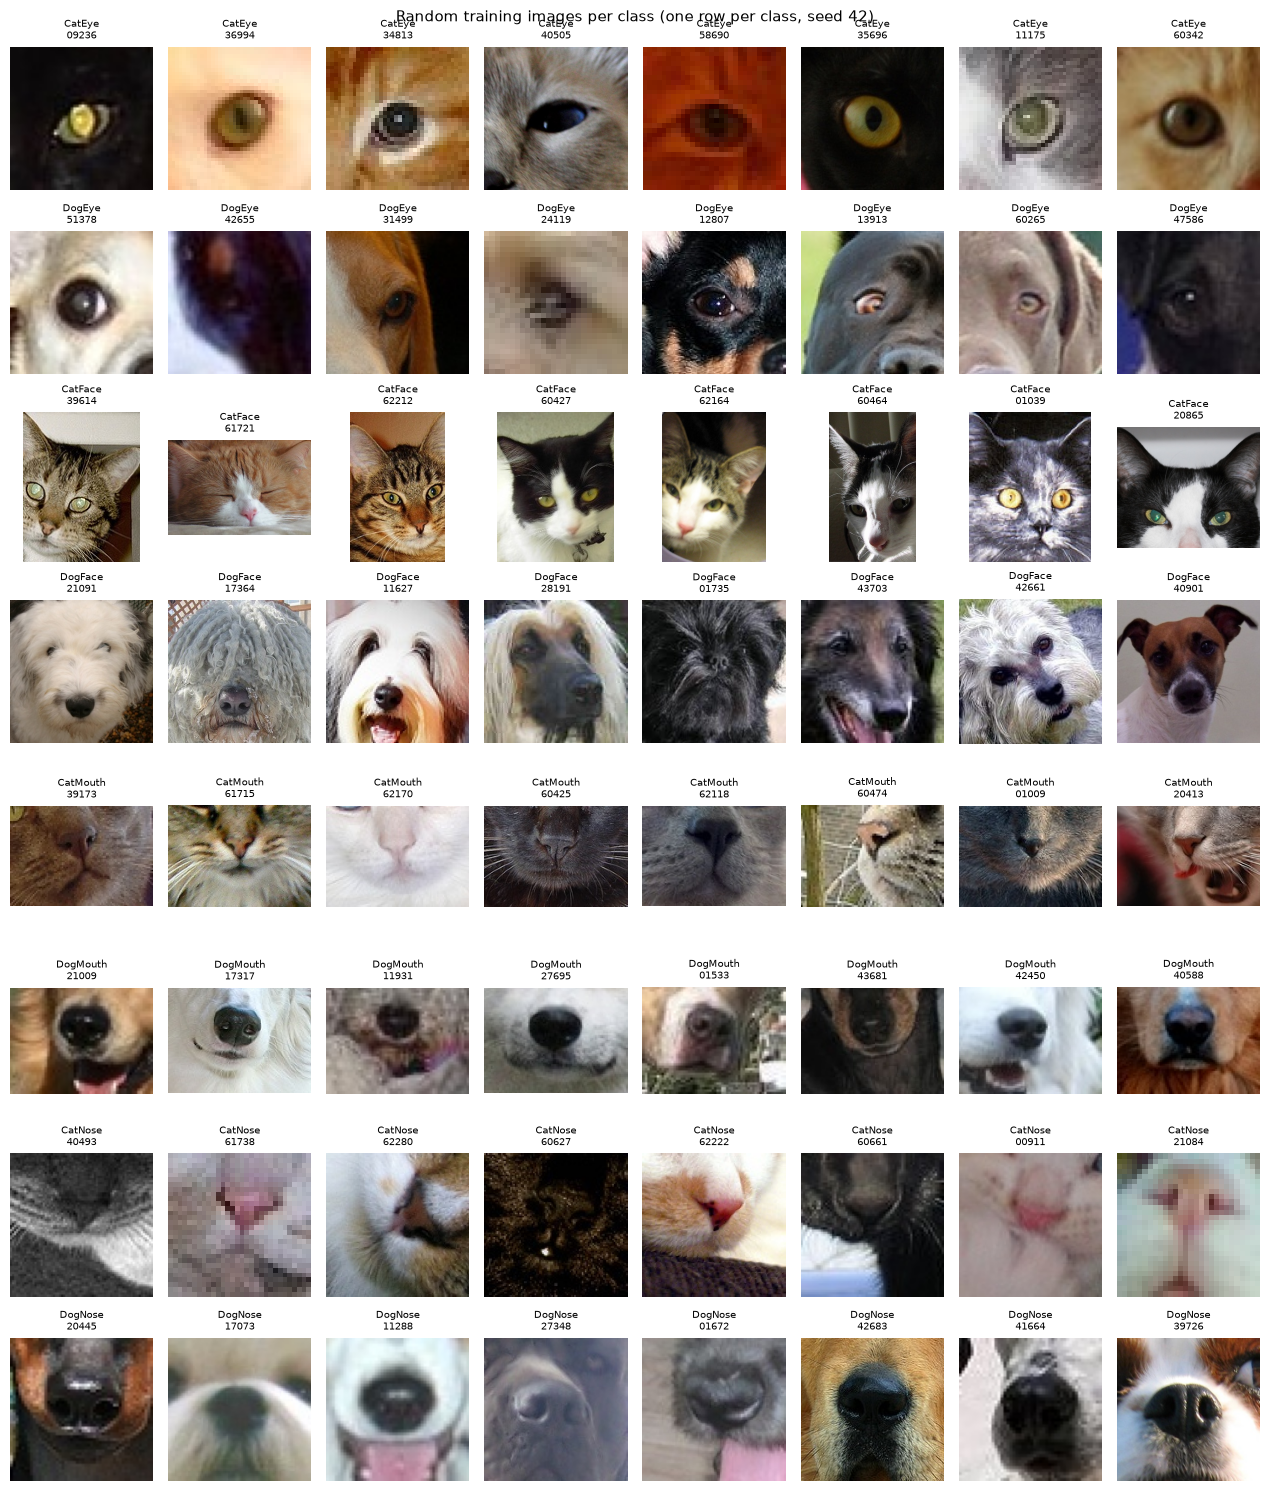


SUMMARY
                                        Check         Result                          Note
                              Corrupted files              0    Could not be fully decoded
                 Distinct image sizes (train)           7861            Width 4 to 2219 px
                     Blurriest images flagged            932        Bottom 1% of sharpness
            Very dark / bright / near-uniform 531 / 80 / 141 Mean < 20, mean > 235, sd < 8
               Exact duplicate groups (train)             15          Identical file bytes
                Near-duplicate groups (train)             40     Identical perceptual hash
Near-duplicate groups with conflicting labels              0 Same picture, different class
           Train pictures also in test (near)              2   Possible train/test overlap


In [ ]:
"""03 Data Exploration: Data Quality

Checks the training and test images for the data quality issues listed in the brief (report Task 1.6):
  1. Corrupted files        every image is fully decoded, not just its header
  2. Inconsistent sizes     width, height and aspect ratio distributions, per class
  3. Blurry images          sharpness score (variance of the Laplacian)
  4. Blank or extreme images very dark, very bright or near-uniform images
  5. Duplicate images       exact duplicates (file hash) and near duplicates (perceptual hash),
                            within train, across classes, and between train and test
  6. Unclear class boundaries  visual grids of the most suspicious images for manual review

All per-image measurements are saved to outputs/quality_metrics.csv, and figures go to outputs/figures/.
On the full dataset the measurement pass takes a few minutes; progress is printed as it runs.

Run from the project folder:  python 03_data_quality.py
Requires: pandas, numpy, matplotlib, pillow
"""

# %% Configuration
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("data")                      # same setting as the earlier scripts
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
CLASS_ORDER = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]

SHARPNESS_SIZE = 128     # images are resized to this before scoring sharpness, so scores are comparable
BLUR_PERCENTILE = 1      # the blurriest 1% are flagged for review (a relative threshold, not an absolute one)
DARK_THRESHOLD = 20      # mean brightness (0 to 255) below this counts as very dark
BRIGHT_THRESHOLD = 235   # mean brightness above this counts as very bright
LOW_CONTRAST_STD = 8     # pixel standard deviation below this counts as near-uniform

train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
labels = dict(zip(train_df["image_id"], train_df["class"]))

def find_images(folder):
    return sorted(f for f in folder.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS)

files = [("train", f) for f in find_images(TRAIN_DIR)] + [("test", f) for f in find_images(TEST_DIR)]
print(f"Images to check: {len(files)} "
      f"(train {sum(s == 'train' for s, _ in files)}, test {sum(s == 'test' for s, _ in files)})")

# %% Measurement pass
# One pass over every image computes all the measurements, so each file is only read once.

LAPLACIAN_STEPS = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def laplacian_variance(grey):
    """Variance of the 4-neighbour Laplacian. Low values mean few sharp edges, i.e. blur."""
    g = grey.astype(np.float32)
    lap = -4 * g[1:-1, 1:-1]
    for dy, dx in LAPLACIAN_STEPS:
        lap += g[1 + dy:g.shape[0] - 1 + dy, 1 + dx:g.shape[1] - 1 + dx]
    return float(lap.var())

def dhash(img, size=8):
    """Difference hash: a 64-bit fingerprint that stays the same when an image is resized,
    recompressed or slightly altered, so matching hashes indicate near-duplicate images."""
    small = np.asarray(img.convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return "".join("1" if b else "0" for b in bits)

records = []
start = time.time()
for i, (split, path) in enumerate(files, 1):
    rec = {"split": split, "image_id": path.stem, "path": str(path),
           "label": labels.get(path.stem) if split == "train" else None, "error": None}
    try:
        raw = path.read_bytes()
        rec["md5"] = hashlib.md5(raw).hexdigest()
        rec["file_kb"] = len(raw) / 1024
        with Image.open(path) as img:
            img.load()                                   # forces a full decode, which exposes truncated files
            rec.update(width=img.width, height=img.height, mode=img.mode)
            rgb = img.convert("RGB")
        grey = np.asarray(rgb.convert("L"), dtype=np.float32)
        rec["brightness"] = float(grey.mean())
        rec["contrast"] = float(grey.std())
        sharp_grey = np.asarray(rgb.convert("L").resize((SHARPNESS_SIZE, SHARPNESS_SIZE)))
        rec["sharpness"] = laplacian_variance(sharp_grey)
        rec["dhash"] = dhash(rgb)
    except Exception as e:
        rec["error"] = f"{type(e).__name__}: {e}"
    records.append(rec)
    if i % 5000 == 0 or i == len(files):
        print(f"  {i}/{len(files)} images  ({time.time() - start:.0f}s)")

q = pd.DataFrame(records)
for col in ["width", "height"]:
    q[col] = q[col].astype("Int64")      # whole numbers even when a corrupted row leaves a gap
q["aspect"] = q["width"] / q["height"]
q.to_csv(OUTPUT_DIR / "quality_metrics.csv", index=False)
ok = q[q["error"].isna()].copy()
train_ok = ok[ok["split"] == "train"]

# Helper for image grids used throughout
def show_grid(rows, title, filename, n_cols=8, caption=None):
    rows = list(rows.itertuples()) if isinstance(rows, pd.DataFrame) else list(rows)
    if not rows:
        print(f"  (no images to show for: {title})")
        return
    n_rows = int(np.ceil(len(rows) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.6, n_rows * 1.9), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, rows):
        with Image.open(r.path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(caption(r) if caption else f"{r.image_id}\n{r.label or r.split}",
                     fontsize=7)
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    print(f"  saved {FIG_DIR / filename}")
    plt.show()

# %% 1. Corrupted files
errors = q[q["error"].notna()]
print(f"\n1. CORRUPTED FILES: {len(errors)} of {len(q)} images could not be fully decoded")
if len(errors):
    print(errors[["split", "image_id", "error"]].to_string(index=False))

# %% 2. Image sizes and aspect ratios
print("\n2. IMAGE SIZES")
for split, g in ok.groupby("split"):
    print(f"  [{split}] distinct sizes: {g.groupby(['width', 'height']).ngroups}, "
          f"width {g['width'].min()} to {g['width'].max()} (median {g['width'].median():.0f}), "
          f"height {g['height'].min()} to {g['height'].max()} (median {g['height'].median():.0f}), "
          f"non-square: {(g['width'] != g['height']).mean() * 100:.1f}%")
    top = g.groupby(["width", "height"]).size().sort_values(ascending=False).head(5)
    print("    most common sizes: " + ", ".join(f"{w}x{h} ({n})" for (w, h), n in top.items()))
    print(f"    colour modes: {g['mode'].value_counts().to_dict()}")

print("\n  Median size per class (train). Large differences mean size alone could reveal the class:")
by_class = train_ok.groupby("label")[["width", "height", "aspect"]].median().reindex(CLASS_ORDER)
print(by_class.astype(float).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for split, colour in [("train", "#4C72B0"), ("test", "#DD8452")]:
    g = ok[ok["split"] == split]
    axes[0].scatter(g["width"], g["height"], s=3, alpha=0.3, color=colour, label=split)
axes[0].set_xlabel("Width (px)"); axes[0].set_ylabel("Height (px)")
axes[0].set_title("Image dimensions"); axes[0].legend(markerscale=4, frameon=False)
axes[1].boxplot([train_ok.loc[train_ok["label"] == c, "width"] for c in CLASS_ORDER],
                showfliers=False)
axes[1].set_xticks(range(1, len(CLASS_ORDER) + 1), CLASS_ORDER, rotation=45)
axes[1].set_title("Image width by class (train)"); axes[1].set_xlabel(""); axes[1].set_ylabel("Width (px)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "image_sizes.png", dpi=200)
print(f"  saved {FIG_DIR / 'image_sizes.png'}")
plt.show()

show_grid(train_ok.nsmallest(16, "width"), "Smallest training images", "smallest_images.png",
          caption=lambda r: f"{r.image_id} {r.label}\n{r.width}x{r.height}")

# %% 3. Blurry images
blur_cut = ok["sharpness"].quantile(BLUR_PERCENTILE / 100)
ok["blurry"] = ok["sharpness"] <= blur_cut
print(f"\n3. BLUR: sharpness median {ok['sharpness'].median():.1f}, "
      f"bottom-{BLUR_PERCENTILE}% cut-off {blur_cut:.1f}; {ok['blurry'].sum()} images flagged as blurriest")
print("  Blurriest-1% rate per class (train). An uneven spread suggests some classes are naturally softer:")
rate = ok[ok["split"] == "train"].groupby("label")["blurry"].mean().reindex(CLASS_ORDER) * 100
print("  " + ", ".join(f"{c} {v:.1f}%" for c, v in rate.items()))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(ok["sharpness"] + 1), bins=80, color="#4C72B0")
ax.axvline(np.log10(blur_cut + 1), color="crimson", ls="--", label=f"Bottom {BLUR_PERCENTILE}% cut-off")
ax.set_xlabel("log10(sharpness + 1)"); ax.set_ylabel("Images"); ax.set_title("Sharpness distribution")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "sharpness_distribution.png", dpi=200)
print(f"  saved {FIG_DIR / 'sharpness_distribution.png'}")
plt.show()

show_grid(ok[ok["split"] == "train"].nsmallest(24, "sharpness"), "Blurriest training images",
          "blurriest_images.png",
          caption=lambda r: f"{r.image_id} {r.label}\nsharp {r.sharpness:.1f}")

# %% 4. Blank, very dark, very bright or near-uniform images
dark = ok[ok["brightness"] < DARK_THRESHOLD]
bright = ok[ok["brightness"] > BRIGHT_THRESHOLD]
flat = ok[ok["contrast"] < LOW_CONTRAST_STD]
print(f"\n4. EXPOSURE: very dark {len(dark)}, very bright {len(bright)}, near-uniform {len(flat)}")
extreme = pd.concat([dark, bright, flat]).drop_duplicates("path")
show_grid(extreme.head(24), "Very dark, very bright or near-uniform images", "extreme_exposure.png",
          caption=lambda r: f"{r.image_id} {r.label or r.split}\n"
                            f"mean {r.brightness:.0f} sd {r.contrast:.0f}")

# %% 5. Duplicates
# Exact duplicates share a file hash (byte-for-byte identical).
# Near duplicates share a perceptual hash (same picture after resizing or recompression).
print("\n5. DUPLICATES")

def duplicate_groups(df, key):
    groups = df[df.duplicated(key, keep=False)].groupby(key)
    return [g for _, g in groups]

for key, name in [("md5", "Exact"), ("dhash", "Near")]:
    tr_groups = duplicate_groups(train_ok, key)
    n_imgs = sum(len(g) for g in tr_groups)
    conflicting = [g for g in tr_groups if g["label"].nunique() > 1]
    cross = set(train_ok[key]) & set(ok.loc[ok["split"] == "test", key])
    print(f"  {name} duplicates within train: {len(tr_groups)} groups covering {n_imgs} images")
    print(f"    groups whose copies have DIFFERENT labels: {len(conflicting)}")
    print(f"    train images that also appear in test: "
          f"{train_ok[key].isin(cross).sum()} ({len(cross)} distinct pictures)")
    if conflicting:
        print("    examples of conflicting labels:")
        for g in conflicting[:5]:
            print("     ", ", ".join(f"{r.image_id}={r.label}" for r in g.itertuples()))

# The near-duplicate grid shows pairs side by side, label conflicts first, for visual confirmation.
near_groups = duplicate_groups(train_ok, "dhash")
near_groups.sort(key=lambda g: g["label"].nunique(), reverse=True)
pairs = pd.concat([g.head(2) for g in near_groups[:12]]) if near_groups else pd.DataFrame()
show_grid(pairs, "Near-duplicate pairs (each consecutive pair shares a perceptual hash)",
          "near_duplicates.png",
          caption=lambda r: f"{r.image_id}\n{r.label}")

# %% 6. Unclear class boundaries
# There is no automatic test for this. The grids below give material for visual judgement:
# random examples per class, to compare within-class variety with between-class differences.
# Look for crops that could reasonably belong to another class, e.g. tight face crops
# that resemble nose crops, or eye crops too small to show species.
print("\n6. CLASS BOUNDARIES: review the per-class grid for ambiguous examples")
rng_rows = []
for c in CLASS_ORDER:
    rng_rows.append(train_ok[train_ok["label"] == c].sample(n=min(8, (train_ok["label"] == c).sum()),
                                                             random_state=42))
show_grid(pd.concat(rng_rows), "Random training images per class (one row per class, seed 42)",
          "class_samples_review.png", n_cols=8,
          caption=lambda r: f"{r.label}\n{r.image_id}")

# %% Summary for the report
summary = pd.DataFrame([
    ["Corrupted files", len(errors), "Could not be fully decoded"],
    ["Distinct image sizes (train)", train_ok.groupby(["width", "height"]).ngroups,
     f"Width {train_ok['width'].min()} to {train_ok['width'].max()} px"],
    ["Blurriest images flagged", int(ok["blurry"].sum()), f"Bottom {BLUR_PERCENTILE}% of sharpness"],
    ["Very dark / bright / near-uniform", f"{len(dark)} / {len(bright)} / {len(flat)}",
     f"Mean < {DARK_THRESHOLD}, mean > {BRIGHT_THRESHOLD}, sd < {LOW_CONTRAST_STD}"],
    ["Exact duplicate groups (train)", len(duplicate_groups(train_ok, "md5")), "Identical file bytes"],
    ["Near-duplicate groups (train)", len(near_groups), "Identical perceptual hash"],
    ["Near-duplicate groups with conflicting labels", sum(g["label"].nunique() > 1 for g in near_groups),
     "Same picture, different class"],
    ["Train pictures also in test (near)", int(train_ok["dhash"].isin(ok.loc[ok["split"] == "test", "dhash"]).sum()),
     "Possible train/test overlap"],
], columns=["Check", "Result", "Note"])
summary.to_csv(OUTPUT_DIR / "quality_summary.csv", index=False)
pd.set_option("display.width", 200)
print("\nSUMMARY")
print(summary.to_string(index=False))

## Task 2: Data Preprocessing and Pipeline Preparation

### Data Preparation


Project folder: /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment
Labelled training images: 63660
1. Excluded 190 images with shortest side under 16 px -> 63470 remain
2. Duplicate groups: 40 (covering 80 images, 0 with conflicting labels); removed 40 extra copies -> 63430 remain
3. Split: training 50744, validation 12686 (20.0% validation)

   Class proportions in each subset (stratification check):
          train_n  train_%  val_n  val_%  label_idx
label                                              
CatEye      11017    21.71   2754  21.71          0
DogEye       9253    18.23   2313  18.23          1
CatFace      5549    10.94   1387  10.93          2
DogFace      4628     9.12   1157   9.12          3
CatMouth     5527    10.89   1382  10.89          4
DogMouth     4631     9.13   1158   9.13          5
CatNose      5510    10.86   1378  10.86          6
DogNose      4629     9.12   1157   9.12          7

4. Test list: 29443 images, 

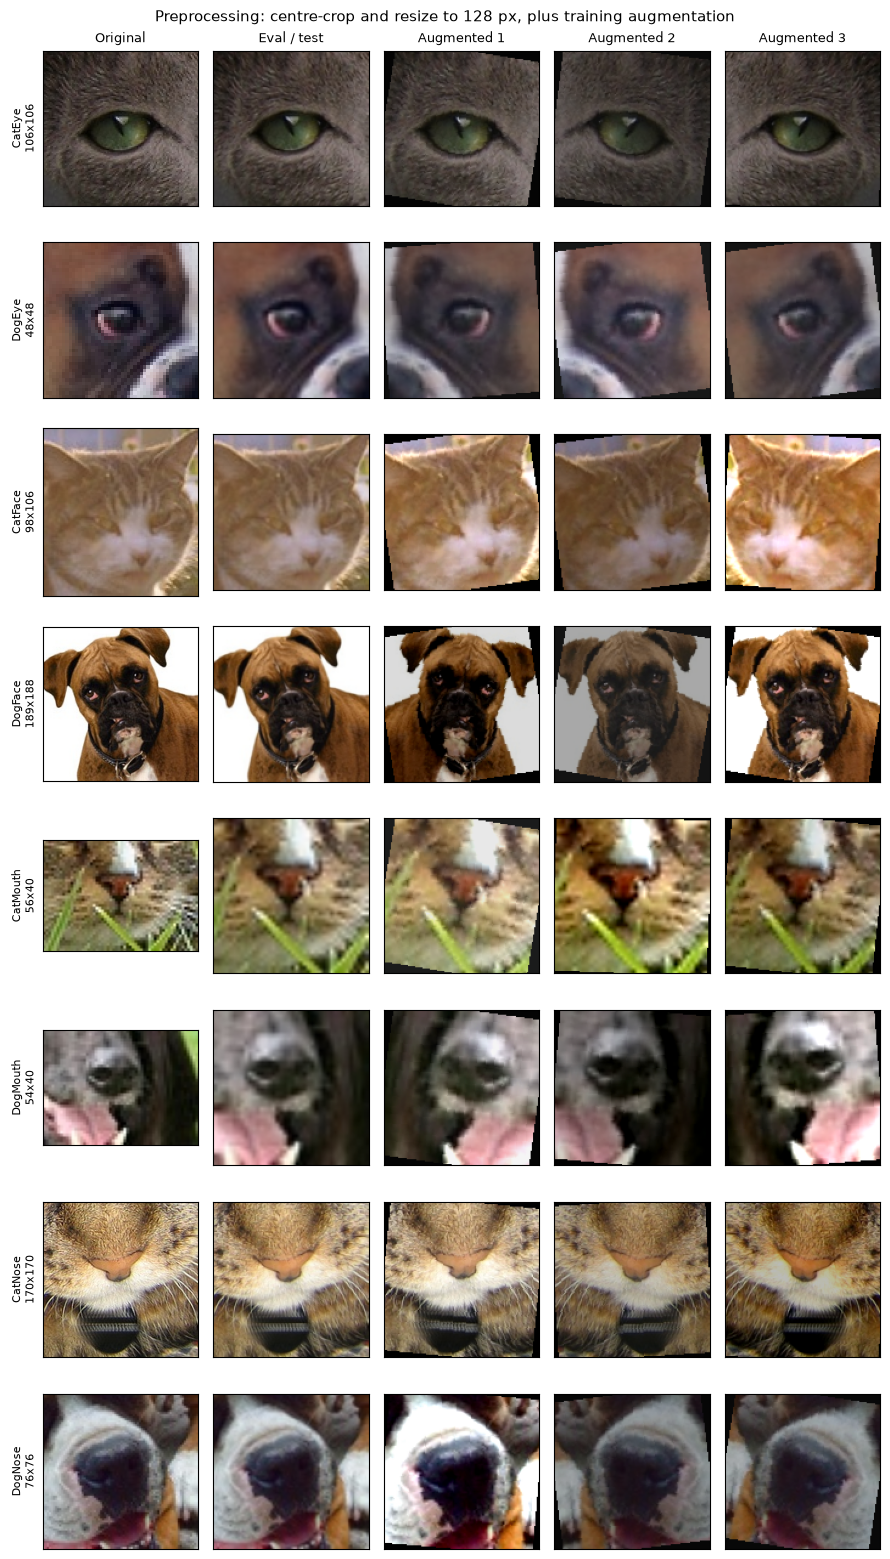

In [ ]:
"""04 Data Preparation: Cleaning, Splitting and Pipeline Checks

Applies the data cleaning decisions from Task 1.6, creates the training/validation split,
and checks that the preprocessing pipeline from preprocessing.py works as intended (report Task 2).

Steps:
  1. Exclude training images whose shortest side is under 16 px
  2. Remove extra copies of duplicate images (exact and near duplicates), keeping one per group
  3. Stratified 80/20 split with a fixed seed, saved to outputs/splits/
  4. Build the test list in sample_submission.csv order
  5. Leakage checks between training, validation and test
  6. Pipeline checks: batch shapes, value ranges, label encoding, loading speed
  7. Figure showing the evaluation and training (augmented) transforms

Requires outputs/quality_metrics.csv from 03_data_quality.py.
Paths are found automatically by preprocessing.py, so this can run from the project folder or src/.
"""

# %% Setup
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

import preprocessing as pp

print(f"Project folder: {pp.PROJECT_ROOT}")
pp.SPLIT_DIR.mkdir(parents=True, exist_ok=True)
pp.FIG_DIR.mkdir(parents=True, exist_ok=True)

labels = pd.read_csv(pp.TRAIN_CSV, dtype={"image_id": str})
quality = pd.read_csv(pp.QUALITY_CSV, dtype={"image_id": str, "label": str}, low_memory=False)

def file_index(folder):
    return {f.stem: pp.relative_path(f) for f in folder.rglob("*") if f.suffix.lower() in pp.IMAGE_EXTENSIONS}

train_paths, test_paths = file_index(pp.TRAIN_DIR), file_index(pp.TEST_DIR)

df = labels.rename(columns={"class": "label"})
df["path"] = df["image_id"].map(train_paths)
df = df.merge(quality.loc[quality["split"] == "train", ["image_id", "width", "height", "md5", "dhash"]],
              on="image_id", how="left")
assert df["path"].notna().all(), "Some labelled images have no file. Re-run 01_data_structure.py."
assert df["md5"].notna().all(), "Some images are missing from quality_metrics.csv. Re-run 03_data_quality.py."
print(f"Labelled training images: {len(df)}")

# %% 1. Exclude tiny images
df["short_side"] = df[["width", "height"]].min(axis=1)
tiny = df["short_side"] < pp.MIN_SIDE
excluded = df.loc[tiny, ["image_id", "label", "short_side"]].assign(reason=f"shortest side < {pp.MIN_SIDE} px")
df = df[~tiny].copy()
print(f"1. Excluded {tiny.sum()} images with shortest side under {pp.MIN_SIDE} px -> {len(df)} remain")

# %% 2. Remove extra copies of duplicates
# Images are linked if they share an exact hash (md5) or a perceptual hash (dhash).
# Linked images form a duplicate group, and only the copy with the lowest image_id is kept.
parent = {i: i for i in df["image_id"]}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for key in ["md5", "dhash"]:
    for _, ids in df.groupby(key)["image_id"]:
        ids = sorted(ids)
        for other in ids[1:]:
            parent[find(other)] = find(ids[0])

df["dup_group"] = df["image_id"].map(find)
group_sizes = df["dup_group"].value_counts()
dup_rows = df[df["dup_group"].map(group_sizes) > 1]
conflicts = dup_rows.groupby("dup_group")["label"].nunique().gt(1).sum()
keep = df.sort_values("image_id").drop_duplicates("dup_group", keep="first")
removed = df[~df["image_id"].isin(keep["image_id"])]
excluded = pd.concat([excluded, removed[["image_id", "label", "short_side"]].assign(
    reason="duplicate of image " + removed["dup_group"])])
df = keep.copy()
print(f"2. Duplicate groups: {(group_sizes > 1).sum()} (covering {len(dup_rows)} images, "
      f"{conflicts} with conflicting labels); removed {len(removed)} extra copies -> {len(df)} remain")

excluded.to_csv(pp.SPLIT_DIR / "excluded.csv", index=False)

# %% 3. Stratified training/validation split
train_df, val_df = train_test_split(df, test_size=pp.VAL_FRACTION, stratify=df["label"],
                                    random_state=pp.SEED)
cols = ["image_id", "path", "label"]
train_df = train_df.sort_values("image_id")[cols]
val_df = val_df.sort_values("image_id")[cols]
train_df.to_csv(pp.SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(pp.SPLIT_DIR / "val.csv", index=False)
pp.save_class_mapping()

print(f"3. Split: training {len(train_df)}, validation {len(val_df)} "
      f"({len(val_df) / (len(train_df) + len(val_df)) * 100:.1f}% validation)")
prop = pd.DataFrame({
    "train_n": train_df["label"].value_counts(),
    "train_%": train_df["label"].value_counts(normalize=True) * 100,
    "val_n": val_df["label"].value_counts(),
    "val_%": val_df["label"].value_counts(normalize=True) * 100,
}).reindex(pp.CLASS_NAMES)
prop["label_idx"] = [pp.CLASS_TO_IDX[c] for c in prop.index]
print("\n   Class proportions in each subset (stratification check):")
print(prop.round(2).to_string())
prop.round(2).to_csv(pp.SPLIT_DIR / "split_summary.csv")

# %% 4. Test list in submission order
sample_sub = pd.read_csv(pp.SAMPLE_SUB_CSV, dtype={"image_id": str})
test_df = pd.DataFrame({"image_id": sample_sub["image_id"]})
test_df["path"] = test_df["image_id"].map(test_paths)

# If exact matching misses, retry by numeric value, which handles zero-padding differences ("1" vs "00001")
if test_df["path"].isna().any():
    by_number = {int(stem): p for stem, p in test_paths.items() if stem.isdigit()}
    numeric = test_df["image_id"].str.strip().where(test_df["image_id"].str.strip().str.isdigit())
    test_df["path"] = test_df["path"].fillna(numeric.dropna().astype(int).map(by_number))

missing = test_df[test_df["path"].isna()]
if len(missing):
    print(f"   {len(missing)} of {len(test_df)} sample_submission IDs have no matching test image.")
    print(f"   Example submission IDs: {missing['image_id'].head(5).tolist()}")
    print(f"   Example test filenames: {sorted(test_paths)[:5]}")
    print(f"   Test images found: {len(test_paths)} in {pp.TEST_DIR}")
    raise SystemExit("Fix the mismatch above before continuing (send this output if unsure).")
test_df.to_csv(pp.SPLIT_DIR / "test.csv", index=False)
print(f"\n4. Test list: {len(test_df)} images, in sample_submission.csv order")

# %% 5. Leakage checks
def check(description, passed, detail=""):
    print(f"   [{'PASS' if passed else 'FAIL'}] {description} {detail}")

print("\n5. Leakage checks")
hashes = df.set_index("image_id")[["md5", "dhash"]]
tr_h, va_h = hashes.loc[train_df["image_id"]], hashes.loc[val_df["image_id"]]
test_q = quality[quality["split"] == "test"]
check("No image ID appears in both training and validation:",
      not set(train_df["image_id"]) & set(val_df["image_id"]))
check("No exact duplicate shared between training and validation:",
      not set(tr_h["md5"]) & set(va_h["md5"]))
check("No near duplicate shared between training and validation:",
      not set(tr_h["dhash"]) & set(va_h["dhash"]))
check("No file path shared between labelled data and test:",
      not set(df["path"]) & set(test_df["path"]))
overlap = int(df["dhash"].isin(test_q["dhash"]).sum())
print(f"   [INFO] Labelled images whose picture also appears in test (outside our control): {overlap}")

# %% 6. Pipeline checks
# num_workers=0 here keeps this check simple; training scripts use parallel workers.
print("\n6. Pipeline checks")
train_loader, val_loader, test_loader = pp.get_loaders(batch_size=64, num_workers=0)
for name, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    x, y = next(iter(loader))
    second = y[:3].tolist() if name != "test" else list(y[:3])
    print(f"   [{name}] batch {tuple(x.shape)}, dtype {x.dtype}, "
          f"values {x.min():.2f} to {x.max():.2f}, mean {x.mean():.2f}, std {x.std():.2f}, "
          f"{'labels' if name != 'test' else 'ids'} e.g. {second}")
check("Eight classes mapped to integers 0-7:", sorted(pp.IDX_TO_CLASS) == list(range(8)), str(pp.CLASS_TO_IDX))
_, y_val = next(iter(val_loader))
check("Validation labels are within 0-7:", int(y_val.min()) >= 0 and int(y_val.max()) <= 7)

start = time.time()
for i, (x, _) in enumerate(train_loader):
    if i == 19:
        break
per_batch = (time.time() - start) / 20
print(f"   [INFO] Loading speed with 0 workers: {per_batch:.2f}s per batch of 64 "
      f"(about {per_batch * len(train_loader) / 60:.1f} min per epoch before any parallel loading)")

# %% 7. Transform preview figure
# For one random image per class: the original, the evaluation transform, and three augmented versions.
eval_tf, train_tf = pp.get_eval_transform(), pp.get_train_transform()
examples = val_df.groupby("label").sample(1, random_state=pp.SEED).set_index("label").loc[pp.CLASS_NAMES]
cols_titles = ["Original", "Eval / test", "Augmented 1", "Augmented 2", "Augmented 3"]
fig, axes = plt.subplots(len(examples), 5, figsize=(9, 2 * len(examples)))
for r, (cls, row) in enumerate(examples.iterrows()):
    with Image.open(pp.PROJECT_ROOT / row["path"]) as img:
        img = img.convert("RGB")
    views = [np.asarray(img), eval_tf(img)] + [train_tf(img) for _ in range(3)]
    for c, v in enumerate(views):
        ax = axes[r, c]
        ax.imshow(v if c == 0 else pp.denormalise(v).permute(1, 2, 0).numpy())
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(cols_titles[c], fontsize=9)
        if c == 0:
            ax.set_ylabel(f"{cls}\n{img.width}x{img.height}", fontsize=8)
fig.suptitle("Preprocessing: centre-crop and resize to 128 px, plus training augmentation", fontsize=11)
plt.tight_layout()
fig.savefig(pp.FIG_DIR / "transform_preview.png", dpi=150)
print(f"\n7. Saved {pp.FIG_DIR / 'transform_preview.png'}")
plt.show()

## Task 3: Model Selection and Pipeline Development

This section defines the models, specifies their inputs and outputs, sets the training configuration, and checks that the full pipeline works end to end before the training runs in Task 4.

The reusable code lives in two modules next to `preprocessing.py`:
- `models.py`: the baseline CNN and the ResNet-50 transfer learning model
- `training.py`: the training loop, evaluation, prediction and submission functions

Keeping this code in `.py` files means Tasks 4 and 5 reuse exactly the same definitions, and it allows parallel data loading on macOS.

**Prerequisite:** the Task 2 cell must have been run, so the split files exist in `outputs/splits/`.

### Setup

In [3]:
# Reload edited .py modules automatically, without restarting the kernel
%load_ext autoreload
%autoreload 2

import pandas as pd
import torch
import matplotlib.pyplot as plt

import preprocessing as pp
from models import build_model, count_parameters
from training import RunConfig, set_seed, overfit_one_batch, predict

set_seed()                       # fixed seed (42) for reproducibility
device = pp.get_device()         # Apple silicon GPU ('mps') when available
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.14.1 | device: mps


### Model architectures

Three model versions are compared, so that the value of transfer learning and of fine-tuning can each be measured (Task 6).

**1. Baseline CNN (trained from scratch).** Four convolutional blocks, each with two 3×3 convolutions followed by batch normalisation and ReLU, then 2×2 max pooling. Channels double from 32 to 256 while the spatial size halves from 128 to 8 px. Global average pooling reduces each channel to one value, followed by dropout (0.3) and a linear output layer with 8 units. Batch normalisation stabilises training and dropout reduces overfitting.

**2. ResNet-50, frozen backbone.** ResNet-50 pretrained on ImageNet (1.2 million images, 1,000 classes). Its residual (skip) connections let a 50-layer network train reliably, and its pretrained layers already detect general visual features such as edges, textures and shapes. The original 1,000-class output layer is replaced by dropout (0.2) and a new 8-unit linear layer. Only this new layer is trained, so the pretrained features are used as they are.

**3. ResNet-50, fine-tuned.** Starts from run 2's weights, then trains every layer with a small learning rate, adapting the pretrained features to cat and dog facial features.

ResNet-50 was chosen as a well-established architecture that performs well at small input sizes and is available pretrained in torchvision. Vision Transformers were not chosen because they typically need larger inputs and more data to outperform CNNs, and at 128 px they lose much of their advantage.

In [4]:
baseline = build_model("baseline_cnn")
resnet_frozen = build_model("resnet50_frozen")     # downloads ImageNet weights on first use (about 100 MB)
resnet_finetune = build_model("resnet50_finetune")

print(baseline)

param_table = pd.DataFrame(
    [(name, *count_parameters(m)) for name, m in
     [("Baseline CNN", baseline), ("ResNet-50 frozen", resnet_frozen), ("ResNet-50 fine-tuned", resnet_finetune)]],
    columns=["Model", "Total parameters", "Trainable parameters"])
param_table.style.format({"Total parameters": "{:,}", "Trainable parameters": "{:,}"})

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /Users/christian/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100.0%


BaselineCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, 

,Model,Total parameters,Trainable parameters
0,Baseline CNN,"1,175,272","1,175,272"
1,ResNet-50 frozen,"23,524,424","16,392"
2,ResNet-50 fine-tuned,"23,524,424","23,524,424"


### Input and output specification

| Item | Specification |
|---|---|
| Input | RGB image, 3 × 128 × 128, normalised with ImageNet mean and standard deviation |
| Output layer | Linear layer with 8 units, one per class |
| Output activation | Softmax, applied at prediction time to turn the 8 outputs (logits) into probabilities |
| Hidden activation | ReLU |
| Target classes | 8 (CatEye, DogEye, CatFace, DogFace, CatMouth, DogMouth, CatNose, DogNose) |

The models output raw logits rather than probabilities because PyTorch's cross-entropy loss applies softmax internally, which is more numerically stable. The cell below passes one real batch through each model to confirm the shapes.

In [5]:
_, val_loader, test_loader = pp.get_loaders(batch_size=64, num_workers=0)
x, y = next(iter(val_loader))
print(f"Input batch: {tuple(x.shape)}  (batch, channels, height, width)")

for name, m in [("Baseline CNN", baseline), ("ResNet-50", resnet_finetune)]:
    m.eval()
    with torch.no_grad():
        logits = m(x)
    probs = torch.softmax(logits, dim=1)
    print(f"{name}: output {tuple(logits.shape)} logits | softmax rows sum to {probs.sum(1).mean():.3f}")

# Example: class probabilities for the first image (untrained model, so the values are not meaningful yet)
pd.DataFrame({"class": pp.CLASS_NAMES, "probability": probs[0].numpy().round(3)}).set_index("class").T

Input batch: (64, 3, 128, 128)  (batch, channels, height, width)
Baseline CNN: output (64, 8) logits | softmax rows sum to 1.000
ResNet-50: output (64, 8) logits | softmax rows sum to 1.000


class,CatEye,DogEye,CatFace,DogFace,CatMouth,DogMouth,CatNose,DogNose
probability,0.09,0.125,0.095,0.169,0.113,0.095,0.198,0.115


### Training configuration

| Setting | Choice | Justification |
|---|---|---|
| Loss | Cross-entropy, label smoothing 0.1 | Standard loss for single-label multi-class problems. Smoothing slightly softens the targets, discouraging overconfidence on ambiguous crops such as eyes versus noses |
| Optimiser | AdamW | Adapts the learning rate per parameter and applies weight decay correctly, the standard choice for training and fine-tuning CNNs |
| Weight decay | 1e-4 | Mild regularisation that penalises large weights to reduce overfitting |
| Learning rate | 1e-3 (baseline and frozen head), 1e-4 (fine-tuning) | New layers can learn quickly; pretrained layers need small updates so their learned features are not destroyed |
| LR schedule | Cosine decay | Lowers the learning rate smoothly, allowing large steps early and fine adjustments late |
| Batch size | 64 | Stable gradient estimates while fitting comfortably in the M3's memory |
| Epochs | Maximum 25 (baseline), 5 (frozen), 15 (fine-tuning) | The baseline learns from scratch and needs longer; the frozen run trains one layer and converges fast |
| Early stopping | Patience 4 (3 for frozen) on validation loss | Stops when the model stops generalising better, so the effective number of epochs is set by the data |
| Checkpoint | Best validation accuracy | Accuracy is the Kaggle metric, so the submitted weights are those that scored best on it |

In [6]:
RUNS = [
    RunConfig(name="run1_baseline_cnn",  model="baseline_cnn",      lr=1e-3, epochs=25, patience=4),
    RunConfig(name="run2_resnet50_frozen", model="resnet50_frozen", lr=1e-3, epochs=5,  patience=3),
    RunConfig(name="run3_resnet50_finetune", model="resnet50_finetune", lr=1e-4, epochs=15, patience=4,
              init_from="run2_resnet50_frozen"),
]
pd.DataFrame([vars(r) for r in RUNS]).set_index("name")

,model,lr,epochs,weight_decay,label_smoothing,patience,batch_size,num_workers,init_from
name,,,,,,,,,
run1_baseline_cnn,baseline_cnn,0.0010,25,0.0001,0.1,4,64,4,NaN
run2_resnet50_frozen,resnet50_frozen,0.0010,5,0.0001,0.1,3,64,4,NaN
run3_resnet50_finetune,resnet50_finetune,0.0001,15,0.0001,0.1,4,64,4,run2_resnet50_frozen


### Pipeline sanity check: overfitting one batch

Before full training, each model is trained repeatedly on a single batch of 64 images. A correctly connected model, loss and optimiser should drive the loss close to zero and reach (or come very close to) 100% accuracy on that batch. If it cannot, there is a bug in the pipeline rather than a modelling problem. This is a standard check that catches errors cheaply before committing to long training runs.

Baseline CNN: loss 2.208 -> 0.0015 | accuracy on the batch 100%
ResNet-50: loss 2.113 -> 0.0000 | accuracy on the batch 100%


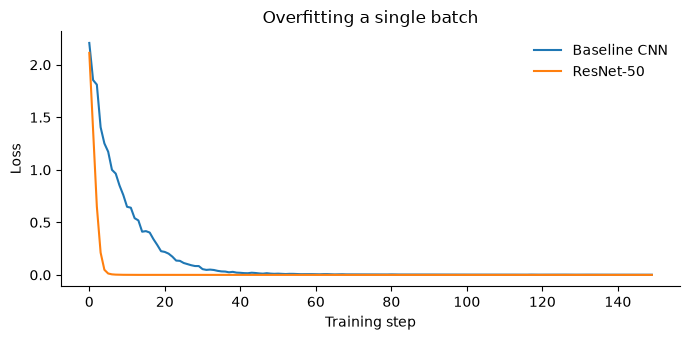

In [7]:
train_loader, _, _ = pp.get_loaders(batch_size=64, num_workers=0)
xb, yb = next(iter(train_loader))

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, model_type in [("Baseline CNN", "baseline_cnn"), ("ResNet-50", "resnet50_finetune")]:
    set_seed()
    losses, acc = overfit_one_batch(build_model(model_type), xb, yb, device, steps=150)
    print(f"{name}: loss {losses[0]:.3f} -> {losses[-1]:.4f} | accuracy on the batch {acc:.0%}")
    ax.plot(losses, label=name)
ax.set_xlabel("Training step"); ax.set_ylabel("Loss"); ax.set_title("Overfitting a single batch")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(pp.FIG_DIR / "overfit_one_batch.png", dpi=150)
plt.show()

### Prediction check

This confirms the pipeline can produce Kaggle predictions end to end: test images are loaded in `sample_submission.csv` order, passed through a model, and converted back to class names. An untrained model is used here, so the predicted classes are meaningless; only the format is being checked. Full predictions with the trained model are generated in Task 5.

In [8]:
preview = predict(baseline.to(device), test_loader, device, max_batches=1)
sample = pd.read_csv(pp.SAMPLE_SUB_CSV, dtype={"image_id": str})

same_order = (preview["image_id"].values == sample["image_id"].values[:len(preview)]).all()
valid_names = set(preview["class"]) <= set(pp.CLASS_NAMES)
print(f"IDs match sample_submission order: {same_order} | all class names valid: {valid_names}")
preview[["image_id", "class"]].head()

IDs match sample_submission order: True | all class names valid: True


,image_id,class
0,1,DogFace
1,2,DogFace
2,3,DogFace
3,4,DogFace
4,5,DogFace


## Task 4: Training Strategy and Overfitting/Underfitting Management

## Task 5: Model Evaluation and Kaggle Submission

## Task 6: Results Analysis and Improvement Strategies